<a href="https://colab.research.google.com/github/dureks23/oss_practice_5/blob/main/oss261104.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TensorFlow 버전: 2.21.0


Saving flower_dataset.zip to flower_dataset.zip
압축 해제 완료!
데이터 경로: /content/flower_dataset/flower_dataset
morning_glory: 9장
cactus: 9장
rose: 9장
Found 27 files belonging to 3 classes.
Using 22 files for training.
Found 27 files belonging to 3 classes.
Using 5 files for validation.


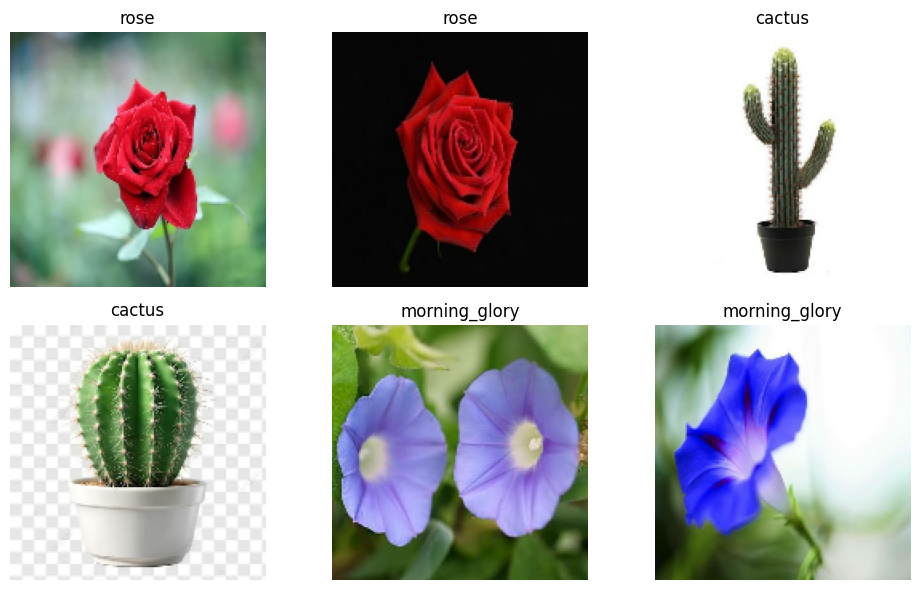

데이터 전처리 완료!


In [10]:

# ============================================
# 1. 라이브러리 불러오기
# ============================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile

from google.colab import files

print("TensorFlow 버전:", tf.__version__)


# ============================================
# 2. ZIP 파일 업로드 및 압축 해제
# ============================================

uploaded = files.upload()

zip_path = next(iter(uploaded.keys()))

extract_path = '/content/flower_dataset'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("압축 해제 완료!")


# ============================================
# 3. 분류할 식물 종류 설정
# ============================================

categories = [
    'morning_glory',
    'cactus',
    'rose'
]

dataset_path = None

for root, dirs, files_list in os.walk(extract_path):
    if all(category in dirs for category in categories):
        dataset_path = root
        break

if dataset_path is None:
    raise ValueError("데이터셋 폴더 구조를 확인해주세요.")

print("데이터 경로:", dataset_path)


# ============================================
# 4. 이미지 개수 확인
# ============================================

for category in categories:

    folder = os.path.join(dataset_path, category)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith(
            ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
        )
    ])

    print(f"{category}: {count}장")

    if count < 2:
        raise ValueError(
            f"{category} 사진이 너무 적습니다."
        )


# ============================================
# 5. 이미지 데이터 불러오기
# ============================================

IMG_SIZE = (160, 160)
BATCH_SIZE = 6
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    labels='inferred',
    label_mode='int',
    class_names=categories,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='training',
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    labels='inferred',
    label_mode='int',
    class_names=categories,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='validation',
    seed=SEED
)


# ============================================
# 6. 이미지 샘플 확인
# ============================================

plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):

    for i in range(len(images)):

        plt.subplot(2, 3, i + 1)

        plt.imshow(
            images[i].numpy().astype('uint8')
        )

        plt.title(
            categories[labels[i].numpy()]
        )

        plt.axis('off')

plt.tight_layout()
plt.show()


# ============================================
# 7. 데이터 성능 최적화
# ============================================

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.prefetch(
    buffer_size=AUTOTUNE
)

print("데이터 전처리 완료!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 652ms/step - accuracy: 0.3182 - loss: 1.4099 - val_accuracy: 0.6000 - val_loss: 0.8991
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.3182 - loss: 1.3317 - val_accuracy: 0.6000 - val_loss: 0.8642
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4545 - loss: 1.3659 - val_accuracy: 0.8000 - val_loss: 0.8308
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.3636 - loss: 1.3854 - val_accuracy: 0.8000 - val_loss: 0.8001
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5455 - loss: 1.0936 - val_accuracy: 0.8000 - val_loss: 0.7699
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4091 - loss: 0.9806 - val_accuracy: 0.8000 - val_loss: 0.7410
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5000 - loss: 1.1949 - val_accuracy: 0.8000 - val_loss: 0.7136
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.4545 - loss: 1.2498 - val_accuracy: 1.0000 - val_loss: 0.690

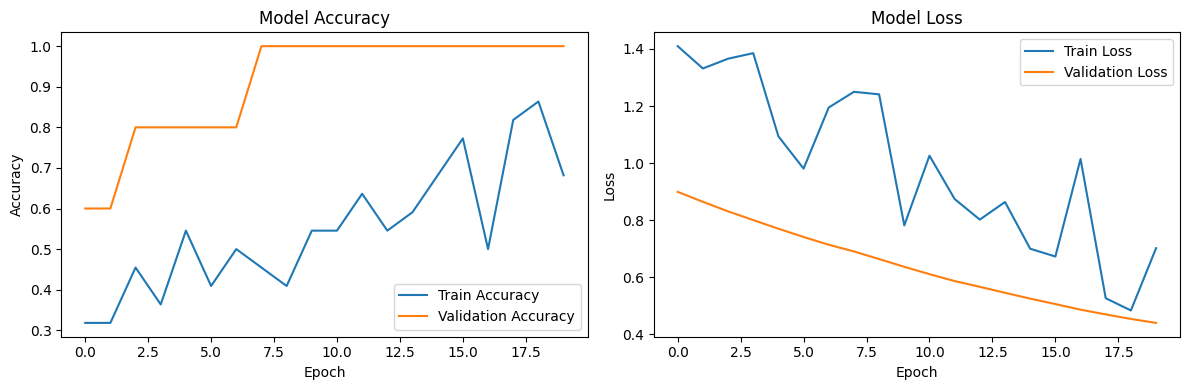

모델 저장 완료!


In [11]:

# ============================================
# 1. 라이브러리 불러오기
# ============================================

from tensorflow.keras import layers, models


# ============================================
# 2. 사전 학습된 MobileNetV2 불러오기
# ============================================

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights='imagenet'
)

# 기존 학습 가중치 고정
base_model.trainable = False


# ============================================
# 3. 데이터 증강
# ============================================

data_augmentation = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])


# ============================================
# 4. 모델 구축
# ============================================

model = models.Sequential([

    layers.Input(shape=(160, 160, 3)),

    # 데이터 증강
    data_augmentation,

    # MobileNetV2 입력 전처리
    layers.Rescaling(
        scale=1./127.5,
        offset=-1
    ),

    # 이미지 특징 추출
    base_model,

    # 특징 데이터 평균화
    layers.GlobalAveragePooling2D(),

    # 과적합 방지
    layers.Dropout(0.3),

    # 3개 식물 분류
    layers.Dense(
        3,
        activation='softmax'
    )
])


# ============================================
# 5. 모델 컴파일
# ============================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


# ============================================
# 6. 모델 학습
# ============================================

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    epochs=20,
    validation_data=val_ds,
    callbacks=[early_stop]
)


# ============================================
# 7. 모델 평가
# ============================================

test_loss, test_acc = model.evaluate(
    val_ds,
    verbose=2
)

print(
    f"검증 정확도: {test_acc * 100:.2f}%"
)


# ============================================
# 8. 학습 결과 그래프
# ============================================

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(
    history.history['accuracy'],
    label='Train Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history.history['loss'],
    label='Train Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


# ============================================
# 9. 모델 저장
# ============================================

model.save('/content/flower_classifier.keras')

print("모델 저장 완료!")


Saving cactus.jpg to cactus (1).jpg
🌱 AI 식물 분류 결과
예측 결과: cactus
예측 확률: 63.43%

[전체 예측 확률]
cactus: 63.43%
rose: 23.30%
morning_glory: 13.27%


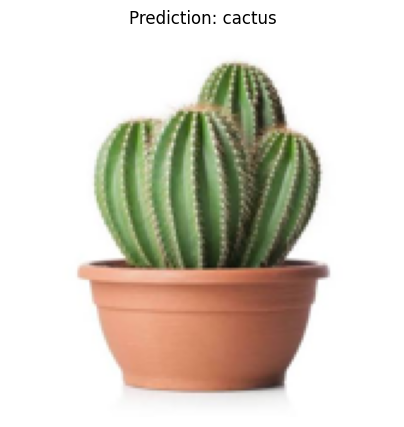

In [15]:

# ============================================
# 1. 필요한 라이브러리
# ============================================

from PIL import Image
from google.colab import files


# ============================================
# 2. 식물 예측 함수
# ============================================

def predict_plant(image_path):

    # 이미지 불러오기
    img = Image.open(image_path).convert('RGB')

    # 이미지 크기 변경
    img = img.resize((160, 160))

    # 배열로 변환
    input_data = np.array(
        img,
        dtype=np.float32
    )

    # 모델 입력 형태로 변환
    input_data = np.expand_dims(
        input_data,
        axis=0
    )

    # AI 예측
    predictions = model.predict(
        input_data,
        verbose=0
    )[0]

    # 가장 높은 확률의 클래스
    predicted_index = np.argmax(predictions)

    predicted_class = categories[predicted_index]

    confidence = predictions[predicted_index] * 100

    # 결과 출력
    print("=" * 40)
    print("🌱 AI 식물 분류 결과")
    print("=" * 40)

    print(f"예측 결과: {predicted_class}")
    print(f"예측 확률: {confidence:.2f}%")

    print("\n[전체 예측 확률]")

    top3 = np.argsort(predictions)[::-1]

    for index in top3:

        print(
            f"{categories[index]}: "
            f"{predictions[index] * 100:.2f}%"
        )

    # 이미지 출력
    plt.figure(figsize=(5, 5))

    plt.imshow(img)

    plt.title(
        f"Prediction: {predicted_class}"
    )

    plt.axis('off')

    plt.show()


# ============================================
# 3. 새로운 사진 업로드
# ============================================

uploaded = files.upload()

for filename in uploaded.keys():

    predict_plant(filename)
